# Set up


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch
!pip install -U timesfm
import timesfm3


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.1/125.1 kB 2.7 MB/s eta 0:00:00


In [2]:
df = pd.read_csv('building_daily_normal_weekdays_features.csv')
df.columns.tolist()
df.head()

,date,mean_kw,max_kw,min_kw,n_points,building,meter_resolution_mode,n_selected_targets,temperature_2m_max,temperature_2m_min,...,temperature_range_c,apparent_temperature_range_c,hdd_x_wind,temp_change_1d_c,temp_change_3d_c,temp_mean_3d_c,temp_mean_7d_c,hdd_sum_3d,hdd_sum_7d,consecutive_cold_days
0,2023-08-21,76.4499,128.575825,25.529357,24,120MapleAve,single,1,76.7,60.4,...,16.3,20.3,0.0,19.6,23.5,58.433333,50.314286,0.0,0.0,0
1,2023-08-22,63.7872,120.075675,25.139080,24,120MapleAve,single,1,74.4,56.7,...,17.7,18.3,0.0,-5.6,10.4,61.900000,53.342857,0.0,0.0,0
2,2023-08-23,63.0951,118.897693,24.621140,24,120MapleAve,single,1,76.9,58.8,...,18.1,17.9,0.0,2.2,16.2,67.300000,57.014286,0.0,0.0,0
3,2023-08-24,59.6511,100.399830,27.390033,24,120MapleAve,single,1,68.5,63.0,...,5.5,9.7,0.0,-0.7,-4.1,65.933333,59.985714,0.0,0.0,0
4,2023-08-25,69.6659,116.836300,26.215885,24,120MapleAve,single,1,76.6,65.6,...,11.0,16.2,0.0,4.4,5.9,67.900000,63.385714,0.0,0.0,0


In [3]:
config = timesfm3.ModelConfig(
    checkpoint_path="google/timesfm-3.0-pytorch",
    device="cpu"
)

forecaster = timesfm3.TimesFM3Evaluator(config)

config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.32GB            

model.safetensors: downloading bytes:           |  0.00B            

# Createing Variables

In [18]:
context_len = 512 # window of past days to look at, max!
horizon = 5 # number of days its predicating
step_size = 5 # move forward the window
weather_cols = ['temp_change_1d_c', # these were from covarince anaylsis
                'windgusts_10m_max',
                'winddirection_10m_dominant',
                'temp_mean_7d_c',
                'apparent_temperature_min',
                'temp_mean_3d_c',
                'cdd_c'] #  cooling degree days

buildings = ['120MapleAve','MorrillHall'] # only a couple to begin with


In [19]:
predictions = []
for b in buildings:

  b_df = df[df['building'] == b].sort_values('date').reset_index(drop=True) # orders them by date, 0 ,1 ,2. need for time series
  # move by the window
  for start_idx in range(0, len(b_df) - context_len - horizon + 1, step_size):
    print(start_idx)
    input = b_df['mean_kw'].values[start_idx : start_idx + context_len] # get the past 512 data
    weather_input = b_df[weather_cols].values[start_idx : start_idx + context_len + horizon].T.astype(np.float32)
    out = list(
            forecaster.predict_batch(
                contexts=[input],
                horizon=horizon,
                past_future_covariates=[weather_input],
                return_quantiles=False # change this to true for the confindnce levels when we are doing treaining
            )
        )
    pred_kw = out[0].forecast.squeeze()
    predictions.append(pred_kw)



0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150
155
160
165
170
175
180


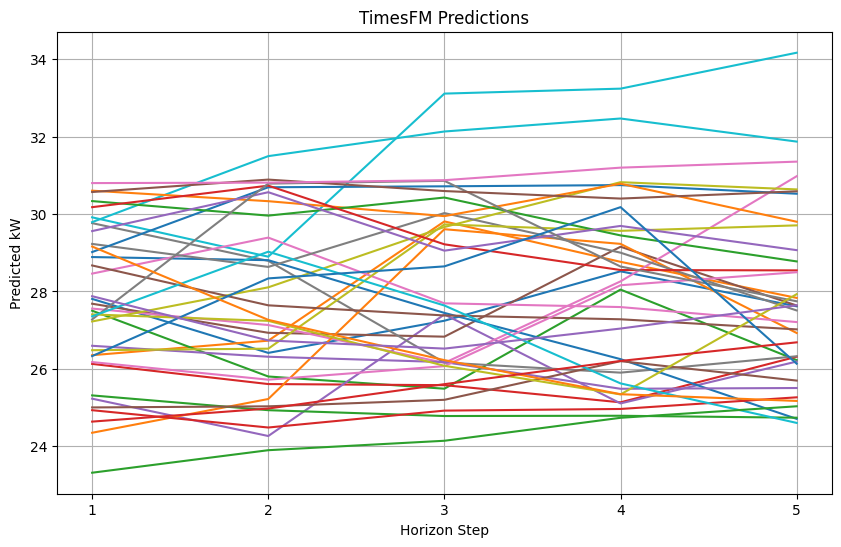

In [20]:
plt.figure(figsize=(10, 6))

x_axis = list(range(1, horizon + 1))

# Plotting each forecast sequence
for i, pred in enumerate(predictions):
    plt.plot(x_axis, pred, label=f'Prediction {i+1}' if i < 10 else "") # limit legend items

plt.xlabel('Horizon Step')
plt.ylabel('Predicted kW')
plt.title('TimesFM Predictions')
plt.xticks(x_axis)
if len(predictions) <= 10:
    plt.legend()
plt.grid(True)
plt.show()

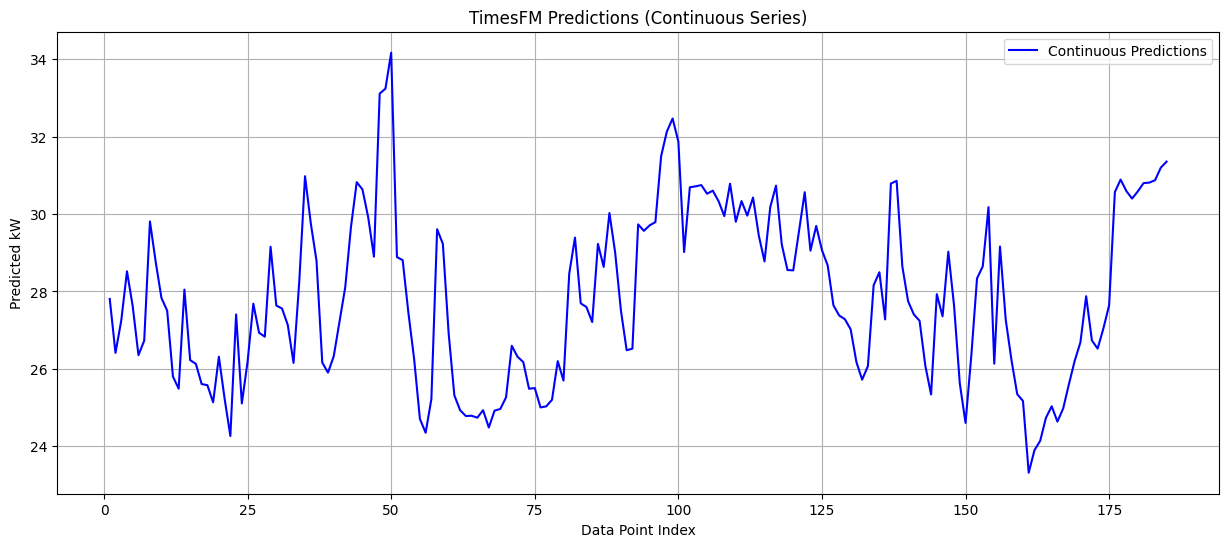

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Concatenate all prediction arrays into a single continuous 1D array
continuous_predictions = np.concatenate(predictions)

# Create the x-axis mapping to 1, 2, 3... up to the total number of points
x_axis_continuous = np.arange(1, len(continuous_predictions) + 1)

# Plot the continuous prediction line
plt.figure(figsize=(15, 6))
plt.plot(x_axis_continuous, continuous_predictions, color='blue', label='Continuous Predictions')
plt.xlabel('Data Point Index')
plt.ylabel('Predicted kW')
plt.title('TimesFM Predictions (Continuous Series)')
plt.grid(True)
plt.legend()
plt.show()

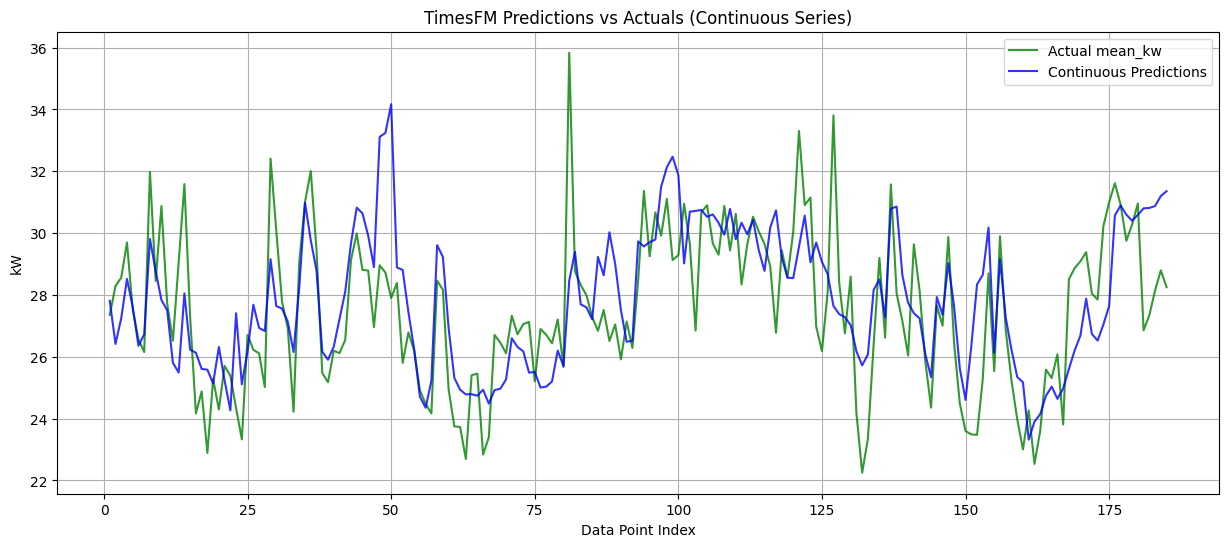

In [22]:
actuals = []

# Recreate the exact same loops to extract the target actuals for the predicted horizons
for b in buildings:
    b_df = df[df['building'] == b].sort_values('date').reset_index(drop=True)
    for start_idx in range(0, len(b_df) - context_len - horizon + 1, step_size):
        # Extract the actual values corresponding to the forecasted horizon
        actual_horizon = b_df['mean_kw'].values[start_idx + context_len : start_idx + context_len + horizon]
        actuals.append(actual_horizon)

# Concatenate all actual arrays into a single continuous 1D array
continuous_actuals = np.concatenate(actuals)

# Plot both the actuals and predictions
plt.figure(figsize=(15, 6))
plt.plot(x_axis_continuous, continuous_actuals, color='green', label='Actual mean_kw', alpha=0.8)
plt.plot(x_axis_continuous, continuous_predictions, color='blue', label='Continuous Predictions', alpha=0.8)
plt.xlabel('Data Point Index')
plt.ylabel('kW')
plt.title('TimesFM Predictions vs Actuals (Continuous Series)')
plt.grid(True)
plt.legend()
plt.show()

Variance of Actuals: 6.2067
Variance of Predictions: 4.8437


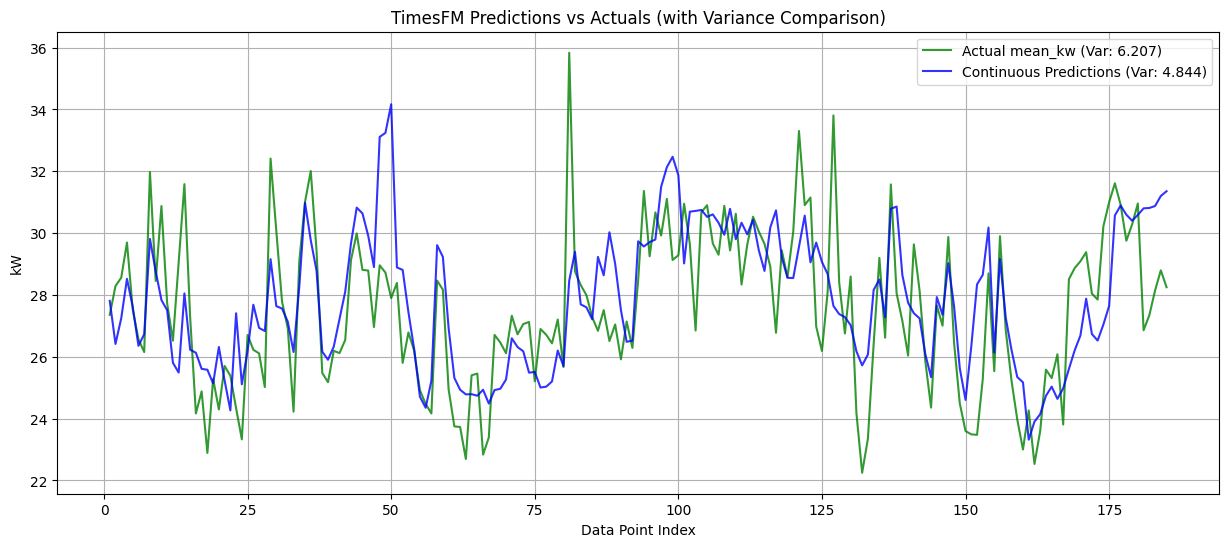

In [23]:
# Calculate the variance for both datasets
variance_actuals = np.var(continuous_actuals)
variance_predictions = np.var(continuous_predictions)

print(f"Variance of Actuals: {variance_actuals:.4f}")
print(f"Variance of Predictions: {variance_predictions:.4f}")

# Plot both the actuals and predictions with variance values in the legend/title
plt.figure(figsize=(15, 6))
plt.plot(x_axis_continuous, continuous_actuals, color='green', label=f'Actual mean_kw (Var: {variance_actuals:.3f})', alpha=0.8)
plt.plot(x_axis_continuous, continuous_predictions, color='blue', label=f'Continuous Predictions (Var: {variance_predictions:.3f})', alpha=0.8)
plt.xlabel('Data Point Index')
plt.ylabel('kW')
plt.title('TimesFM Predictions vs Actuals (with Variance Comparison)')
plt.grid(True)
plt.legend()
plt.show()